# Clustering for Spatial Hotspot Detection
### K-Means vs K-Means++ vs DBSCAN vs HDBSCAN

**Application framing.** We treat clustering as a tool for two different jobs:

| Dataset | Job | Ground truth? |
|---|---|---|
| D1 Earthquakes (USGS) | **Discovery** — find active fault segments / aftershock sequences | No |
| D2 Urban incidents (Chicago) | **Discovery** — find crime hotspots for patrol allocation | Weak proxy (district) |
| D3 Ecoli (UCI) | **Validation** — can unsupervised methods recover known structure? | Yes |

**Central research question.** On D1/D2 no ground truth exists, so we can only use *internal* metrics
(Silhouette, Davies–Bouldin, Calinski–Harabasz). These are known to reward compact convex clusters and
therefore systematically favour K-Means. D3 has labels, so we can check whether internal metrics would have
led us to the *right* method choice. If Silhouette prefers K-Means while ARI prefers DBSCAN, then any
conclusion we draw from internal metrics on the spatial data is suspect.

---
### How to run
1. Run Section 0–1 once with internet: the `sc4020.datasets` loaders cache every file in the repo `data/` folder.
2. Everything after that runs offline.
3. Total runtime on a laptop: a few minutes.

## 0. Setup

In [1]:
import json, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

from sc4020 import methods, tuning
from sc4020.datasets import load_dataset
from sc4020.datasets.preprocess_dataset import EARTH_RADIUS_KM, standardize
from sc4020.datasets.preprocess_dataset import to_radians as lat_lon_to_radians
from sc4020.generate_figures import DPI
from sc4020.metrics import SILHOUETTE_SAMPLE, evaluate
from sc4020.paths import results_dir

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
OUT = results_dir("hotspot") / "notebook"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": DPI,
        "savefig.bbox": "tight",
        "font.size": 9,
        "axes.grid": True,
        "grid.alpha": 0.25,
    }
)

## 1. Data loading

The `sc4020.datasets` loaders cache to the repo `data/` folder. Re-running is free after the first download.

Every loader returns `(df, X, y_true_or_None, meta)` so downstream code is uniform.

### 1.1 D1 — Earthquake epicenters (USGS FDSN Event API)

In [2]:
# Ridgecrest 2019 sequence, Southern California (USGS); downloads into data/ on first use.
eq = load_dataset("ridgecrest_2019")
eq_df, eq_X, eq_y = eq.events, eq.coords_deg, None
eq_meta = dict(
    name="Earthquakes (Ridgecrest 2019)",
    spatial=True,
    units="degrees lat/lon",
    job="discovery",
)
print(eq_df.shape, "events")
eq_df[["time", "latitude", "longitude", "depth", "mag"]].head()

(5635, 22) events


,time,latitude,longitude,depth,mag
0,2019-08-03T22:43:49.130Z,35.808500,-117.640333,1.72,2.12
1,2019-08-03T22:28:42.500Z,36.118667,-117.849167,0.84,2.05
2,2019-08-03T22:17:22.200Z,35.902000,-117.670833,2.85,2.48
3,2019-08-03T21:42:58.570Z,35.776000,-117.595833,2.24,2.14
4,2019-08-03T21:41:55.520Z,35.650333,-117.563167,9.47,2.14


### 1.2 D2 — Urban incidents (Chicago open data, Socrata API)

In [3]:
# Thefts in July 2023 (City of Chicago); coordinates jittered by ~5 m inside the loader so duplicated
# block-level points do not inflate local density for DBSCAN.
chi = load_dataset("chicago_theft", random_state=RANDOM_STATE)
chi_df, chi_X, chi_y = (
    chi.events,
    chi.coords_deg,
    chi.target,
)  # target: police district, a weak proxy
chi_meta = dict(
    name="Chicago THEFT (Jul 2023)",
    spatial=True,
    units="degrees lat/lon",
    job="discovery",
)
print(chi_df.shape, "incidents |", chi_df["district"].nunique(), "police districts")
chi_df.head()

(5188, 8) incidents | 23 police districts


,id,date,primary_type,latitude,longitude,district,community_area,beat
0,13160178,2023-07-31T23:30:00.000,THEFT,41.884110,-87.658045,12,28,1224
1,13160368,2023-07-31T23:30:00.000,THEFT,41.843009,-87.620409,1,35,133
2,13162220,2023-07-31T23:30:00.000,THEFT,41.844216,-87.727410,10,30,1031
3,13160940,2023-07-31T23:20:00.000,THEFT,41.895525,-87.649602,12,24,1214
4,13160093,2023-07-31T23:01:00.000,THEFT,41.727590,-87.585024,4,48,413


> **Caveat to state explicitly in the report.** `district` is an *administrative* boundary, not a natural
> cluster. A high ARI against it would mean the algorithm recovered policing geography, not crime structure.
> We report it as a weak reference only and never treat it as truth.

### 1.3 D3 — Ecoli protein localization (UCI) — the labelled validation set

In [4]:
ec = load_dataset("ecoli", scale=False)
ec_X, ec_y = ec.data, ec.target
ec_df = pd.DataFrame(ec_X, columns=ec.feature_names).assign(
    site=[ec.target_names[i] for i in ec_y]
)
ec_meta = dict(
    name="Ecoli (protein localization)",
    spatial=False,
    units="normalized scores",
    job="validation",
)
print(ec_df.shape)
print(ec_df["site"].value_counts())

(336, 8)
site
cp     143
im      77
pp      52
imU     35
om      20
omL      5
imS      2
imL      2
Name: count, dtype: int64


Note the class imbalance: several localization sites have only 2–5 members. This matters —
DBSCAN will almost certainly label them noise, and whether that is a *failure* or *correct behaviour*
is a real question we answer in Section 8.

### 1.4 Optional — synthetic control (one line, no download)

In [5]:
syn = load_dataset(
    "make_moons", n_samples=1000, noise=0.08, random_state=RANDOM_STATE, scale=False
)
syn_X, syn_y = syn.data, syn.target
syn_meta = dict(
    name="make_moons (control)", spatial=False, units="arbitrary", job="mechanism"
)
print(syn_X.shape)

(1000, 2)


### 1.5 Dataset registry

In [6]:
DATASETS = {
    "earthquakes": dict(X=eq_X, y=eq_y, meta=eq_meta, df=eq_df),
    "chicago": dict(X=chi_X, y=chi_y, meta=chi_meta, df=chi_df),
    "ecoli": dict(X=ec_X, y=ec_y, meta=ec_meta, df=ec_df),
    "moons": dict(X=syn_X, y=syn_y, meta=syn_meta, df=None),
}

summary = pd.DataFrame(
    [
        {
            "dataset": k,
            "n": len(v["X"]),
            "dims": v["X"].shape[1],
            "classes": (len(np.unique(v["y"])) if v["y"] is not None else None),
            "spatial": v["meta"]["spatial"],
            "job": v["meta"]["job"],
        }
        for k, v in DATASETS.items()
    ]
)
summary

,dataset,n,dims,classes,spatial,job
0,earthquakes,5635,2,NaN,True,discovery
1,chicago,5188,2,23.0,True,discovery
2,ecoli,336,7,8.0,False,validation
3,moons,1000,2,2.0,False,mechanism


## 2. Preprocessing

Two decisions that materially change results and deserve a paragraph each in the report.

### 2.1 Distance metric for geographic coordinates

Treating lat/lon as Euclidean distorts distance away from the equator — at Chicago's latitude one degree of
longitude is ~30% shorter than one of latitude. Two valid fixes:

* **Haversine** metric with coordinates in radians (`eps` in radians = km / 6371)
* **Projection** to a local metric CRS so `eps` is directly in metres

We use haversine, which also makes `eps` *interpretable*: "a hotspot is a neighbourhood of events within
300 m". K-Means has no comparable interpretable parameter — `k` is a guess. That is a real practical
argument for DBSCAN in this application, independent of any metric score.

In [7]:
def to_radians(coords):
    return lat_lon_to_radians(coords[:, 0], coords[:, 1])


def km_to_rad(km):
    return km / EARTH_RADIUS_KM


def rad_to_km(rad):
    return rad * EARTH_RADIUS_KM


def preprocess(name, scale=True):
    d = DATASETS[name]
    X, meta = d["X"], d["meta"]
    if meta["spatial"]:
        # spatial: keep raw degrees for plotting, radians for haversine fitting
        return dict(X_fit=to_radians(X), X_plot=X, metric="haversine", spatial=True)
    Xs = standardize(X) if scale else X.astype(float)
    Xp = (
        PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xs)
        if Xs.shape[1] > 2
        else Xs
    )
    return dict(X_fit=Xs, X_plot=Xp, metric="euclidean", spatial=False)


PREP = {k: preprocess(k) for k in DATASETS}
{k: (v["X_fit"].shape, v["metric"]) for k, v in PREP.items()}

{'earthquakes': ((5635, 2), 'haversine'),
 'chicago': ((5188, 2), 'haversine'),
 'ecoli': ((336, 7), 'euclidean'),
 'moons': ((1000, 2), 'euclidean')}

### 2.2 Visualise the raw data

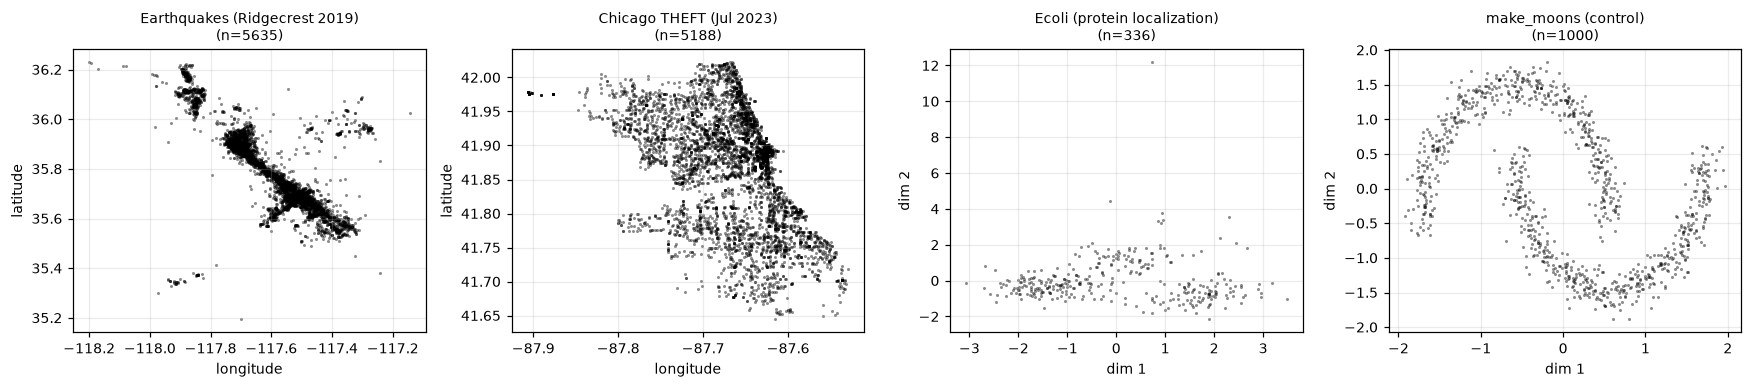

In [8]:
from sc4020.generate_figures import show_and_save_to
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (k, p) in zip(axes, PREP.items()):
    Xp = p["X_plot"]
    ax.scatter(
        Xp[:, 1] if p["spatial"] else Xp[:, 0],
        Xp[:, 0] if p["spatial"] else Xp[:, 1],
        s=4,
        alpha=0.45,
        c="k",
        linewidths=0,
    )
    ax.set_title(f"{DATASETS[k]['meta']['name']}\n(n={len(Xp)})", fontsize=9)
    ax.set_xlabel("longitude" if p["spatial"] else "dim 1")
    ax.set_ylabel("latitude" if p["spatial"] else "dim 2")
plt.tight_layout()
show_and_save_to(plt.gcf(), FIG / "fig1_datasets.png")

## 3. Evaluation harness

One function, used everywhere. Writing this before running any experiment is what keeps four people's
results comparable.

**Noise handling rule:** internal metrics are computed on non-noise points only (they are undefined for a
"noise" pseudo-cluster), while ARI/NMI use all points with noise as its own label. State this in the paper —
it is a real methodological choice that affects the numbers.

In [9]:
# metrics.evaluate: noise excluded from the internal indices; ARI and NMI keep noise as its own group.
def scores(X, lab, y_true=None):
    """metrics.evaluate, with ARI and NMI as NaN when there are no labels."""
    return {"ari": np.nan, "nmi": np.nan, **evaluate(X, lab, y_true)}


def run(estimator, X, y_true=None, **extra):
    lab, dt = methods.fit_predict_timed(estimator, X)
    row = {"runtime_s": round(dt, 4), **extra, **scores(X, lab, y_true)}
    return row, lab


print("harness ready")

harness ready


## 4. Parameter selection

We do **not** hand-tune. Each algorithm gets a documented, reproducible selection procedure — this is what
turns "we picked eps=0.3" into a defensible method section.

### 4.1 k for K-Means — elbow + silhouette

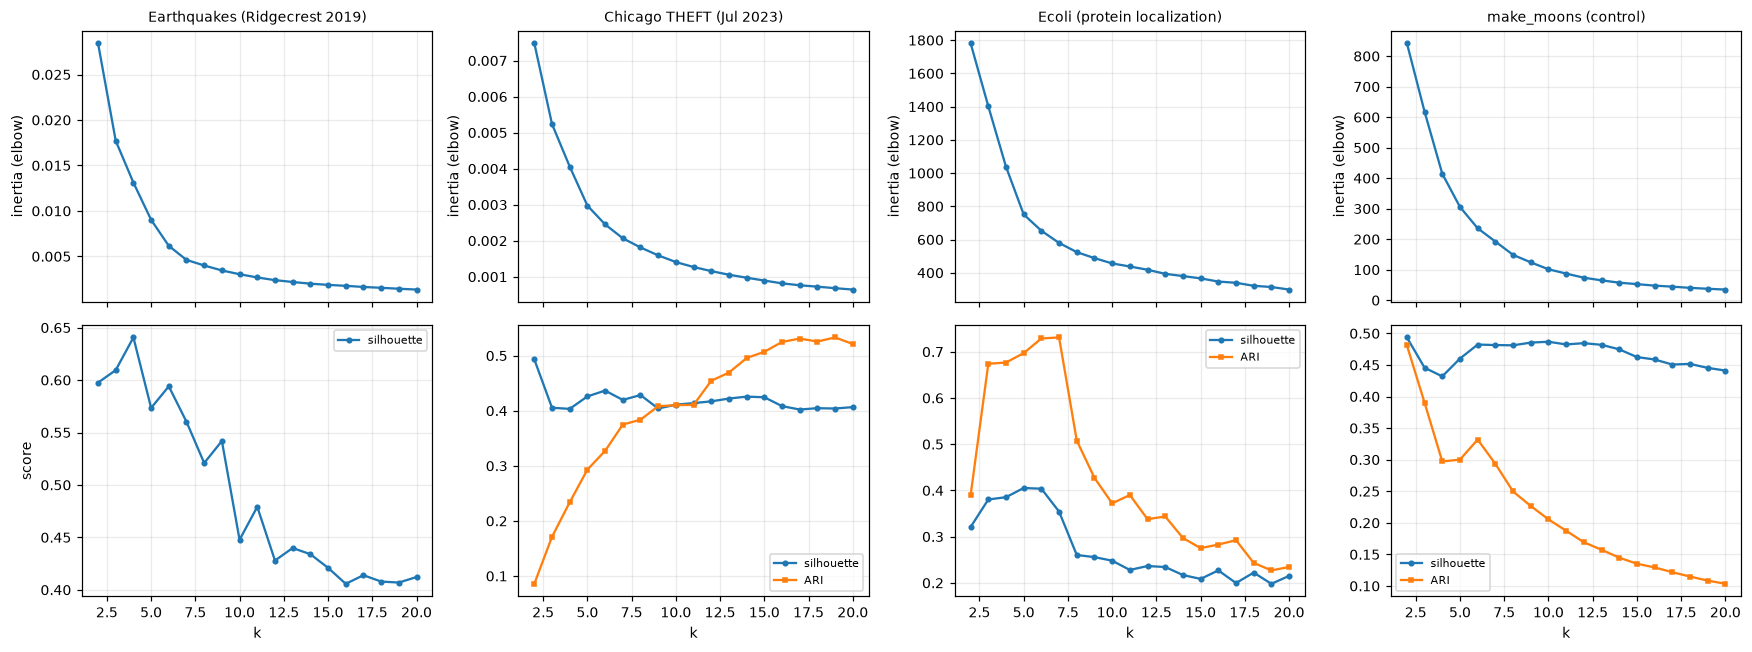

k chosen by the fake-data rule: {'earthquakes': 3, 'chicago': 8, 'ecoli': 5, 'moons': 2}


In [10]:
from sc4020.generate_figures import show_and_save_to
k_choices = {
    name: tuning.select_kmeans_k_by_null_gap(
        PREP[name]["X_fit"],
        k_range=range(2, 21),
        sample_size=SILHOUETTE_SAMPLE,
        random_state=RANDOM_STATE,
        y_true=DATASETS[name]["y"],
    )
    for name in DATASETS
}
k_results = {
    name: pd.DataFrame(choice.tried).rename(columns={"n_clusters": "k"})
    for name, choice in k_choices.items()
}

fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
for j, name in enumerate(DATASETS):
    d = k_results[name]
    axes[0, j].plot(d["k"], d["inertia"], "o-", ms=3)
    axes[0, j].set_title(DATASETS[name]["meta"]["name"], fontsize=9)
    axes[0, j].set_ylabel("inertia (elbow)")
    axes[1, j].plot(d["k"], d["silhouette"], "o-", ms=3, label="silhouette")
    if "ari" in d:
        axes[1, j].plot(d["k"], d["ari"], "s-", ms=3, label="ARI")
    axes[1, j].set_xlabel("k")
    axes[1, j].legend(fontsize=7)
axes[1, 0].set_ylabel("score")
plt.tight_layout()
show_and_save_to(plt.gcf(), FIG / "fig2_k_selection.png")

BEST_K = {name: choice.params["n_clusters"] for name, choice in k_choices.items()}
print("k chosen by the fake-data rule:", BEST_K)

### 4.2 eps for DBSCAN — k-distance curve with automatic knee detection

The standard heuristic: sort each point's distance to its `min_samples`-th neighbour and take the knee.
We detect the knee as the point of maximum perpendicular distance from the chord joining the curve's
endpoints — deterministic and reportable, unlike eyeballing.

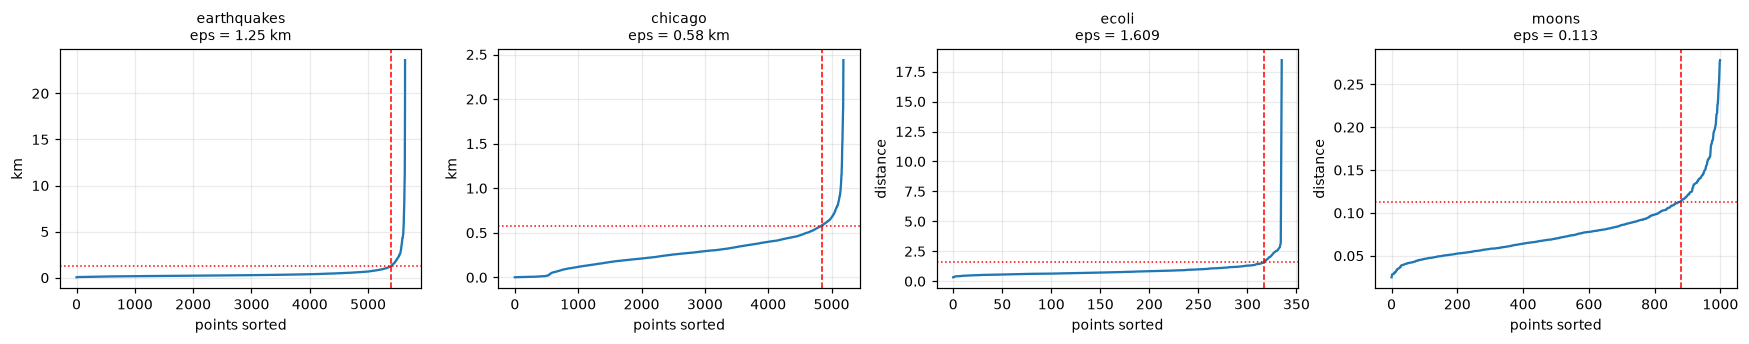

{'earthquakes': 1.249, 'chicago': 0.58, 'ecoli': 1.6088, 'moons': 0.1132}


In [11]:
from sc4020.generate_figures import show_and_save_to
k_distance = tuning.k_distance_curve
knee = tuning.find_knee  # point furthest from the chord, both axes scaled to [0, 1]

EPS = {}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, name in zip(axes, DATASETS):
    p = PREP[name]
    ms = 5
    kd = k_distance(p["X_fit"], ms, metric=p["metric"])
    i, e = knee(kd)
    EPS[name] = e
    disp = rad_to_km(kd) if p["spatial"] else kd
    ax.plot(disp)
    ax.axvline(i, color="r", ls="--", lw=1)
    lbl = f"eps = {rad_to_km(e):.2f} km" if p["spatial"] else f"eps = {e:.3f}"
    ax.axhline(disp[i], color="r", ls=":", lw=1)
    ax.set_title(f"{name}\n{lbl}", fontsize=9)
    ax.set_xlabel("points sorted")
    ax.set_ylabel("km" if p["spatial"] else "distance")
plt.tight_layout()
show_and_save_to(plt.gcf(), FIG / "fig3_kdistance.png")

print(
    {
        n: (round(rad_to_km(e), 3) if PREP[n]["spatial"] else round(e, 4))
        for n, e in EPS.items()
    }
)

### 4.3 Guard: does the knee eps actually produce clusters?

The knee heuristic can fail — on data where density is roughly uniform (which is common in
moderate-dimensional feature spaces like Ecoli) it returns an `eps` so large that DBSCAN merges
everything into one cluster. **This is a finding, not a bug**, and you should report it: it is direct
evidence that the standard DBSCAN heuristic degrades outside low-dimensional spatial data.

Below we keep the knee value, detect the degenerate case, and record a fallback so the comparison
can still proceed. Report both numbers in the paper.

In [12]:
EPS_FALLBACK, EPS_NOTES = {}, {}


def refine_eps(name, min_samples=5, min_clusters=2):
    """Keep the knee eps if it yields >=min_clusters; else search downward and record that it failed."""
    p = PREP[name]
    base = EPS[name]

    def n_clus(e):
        lab = methods.dbscan(e, min_samples, metric=p["metric"]).fit_predict(p["X_fit"])
        return len(set(lab[lab != -1]))

    if n_clus(base) >= min_clusters:
        EPS_NOTES[name] = "knee eps valid"
        return base

    kd = k_distance(p["X_fit"], min_samples, p["metric"])
    for q in [90, 80, 70, 60, 50, 40, 30, 20, 10, 5]:
        e = float(np.percentile(kd, q))
        if n_clus(e) >= min_clusters:
            EPS_NOTES[name] = (
                f"knee eps={base:.4g} degenerate (1 cluster); fell back to {q}th pct"
            )
            print(f"[{name}] {EPS_NOTES[name]}")
            return e
    EPS_NOTES[name] = "no eps in search range produced >=2 clusters"
    print(f"[{name}] {EPS_NOTES[name]}")
    return base


for name in DATASETS:
    EPS_FALLBACK[name] = refine_eps(name)

EPS = EPS_FALLBACK  # used by all downstream sections
pd.DataFrame(
    [
        {
            "dataset": n,
            "eps_used": (
                round(rad_to_km(EPS[n]), 4) if PREP[n]["spatial"] else round(EPS[n], 5)
            ),
            "units": "km" if PREP[n]["spatial"] else "standardized",
            "note": EPS_NOTES[n],
        }
        for n in DATASETS
    ]
)

[ecoli] knee eps=1.609 degenerate (1 cluster); fell back to 60th pct


,dataset,eps_used,units,note
0,earthquakes,1.24870,km,knee eps valid
1,chicago,0.58010,km,knee eps valid
2,ecoli,0.83954,standardized,knee eps=1.609 degenerate (1 cluster); fell ba...
3,moons,0.11323,standardized,knee eps valid


## 5. Main experiment — all methods × all datasets

Writes `results/main_results.csv`. This file is the single source of truth for every number in the report.

In [13]:
def build_methods(name, k, eps, min_samples=5):
    metric = PREP[name]["metric"]
    return {
        "KMeans": (
            methods.kmeans(k, init="random", n_init=10, random_state=RANDOM_STATE),
            dict(params=f"k={k}, init=random"),
        ),
        "KMeans++": (
            methods.kmeans(k, init="k-means++", n_init=10, random_state=RANDOM_STATE),
            dict(params=f"k={k}, init=k-means++"),
        ),
        "DBSCAN": (
            methods.dbscan(eps, min_samples, metric=metric),
            dict(params=f"eps={eps:.5f}, min_samples={min_samples}"),
        ),
        "HDBSCAN": (
            methods.hdbscan(
                max(5, int(0.01 * len(PREP[name]["X_fit"]))), metric=metric
            ),
            dict(params="min_cluster_size=1% of n"),
        ),
    }


rows, LABELS = [], {}
for name in DATASETS:
    p, y = PREP[name], DATASETS[name]["y"]
    for mname, (est, info) in build_methods(name, BEST_K[name], EPS[name]).items():
        r, lab = run(est, p["X_fit"], y, dataset=name, method=mname, **info)
        rows.append(r)
        LABELS[(name, mname)] = lab

main = pd.DataFrame(rows)[
    [
        "dataset",
        "method",
        "params",
        "n_clusters",
        "noise_fraction",
        "silhouette",
        "davies_bouldin",
        "calinski_harabasz",
        "ari",
        "nmi",
        "runtime_s",
    ]
]
main.to_csv(OUT / "main_results.csv", index=False)
main.round(4)

,dataset,method,params,n_clusters,noise_fraction,silhouette,davies_bouldin,calinski_harabasz,ari,nmi,runtime_s
0,earthquakes,KMeans,"k=3, init=random",3,0.0000,0.6074,0.4786,9763.5204,NaN,NaN,1.3738
1,earthquakes,KMeans++,"k=3, init=k-means++",3,0.0000,0.6074,0.4784,9763.5482,NaN,NaN,0.9413
2,earthquakes,DBSCAN,"eps=0.00020, min_samples=5",17,0.0312,-0.3351,0.6810,310.8152,NaN,NaN,0.2057
3,earthquakes,HDBSCAN,min_cluster_size=1% of n,3,0.0293,0.4304,0.6099,2200.0069,NaN,NaN,1.4503
4,chicago,KMeans,"k=8, init=random",8,0.0000,0.4290,0.7885,5965.9225,0.3844,0.6668,2.7192
5,chicago,KMeans++,"k=8, init=k-means++",8,0.0000,0.4289,0.7872,5965.8441,0.3838,0.6666,3.1480
6,chicago,DBSCAN,"eps=0.00009, min_samples=5",32,0.0279,-0.2794,0.7043,50.1218,0.0131,0.1760,0.0906
7,chicago,HDBSCAN,min_cluster_size=1% of n,11,0.7670,0.6637,0.4203,5854.8032,0.0122,0.2990,1.4760
8,ecoli,KMeans,"k=5, init=random",5,0.0000,0.4075,0.7431,176.2105,0.6842,0.6519,0.1888
9,ecoli,KMeans++,"k=5, init=k-means++",5,0.0000,0.4053,0.7466,176.2480,0.6971,0.6663,0.2270


## 6. Qualitative results — where each method visibly succeeds or fails

The most persuasive figure in the paper. A K-Means hotspot drawn over an empty area needs no metric to
make the point.

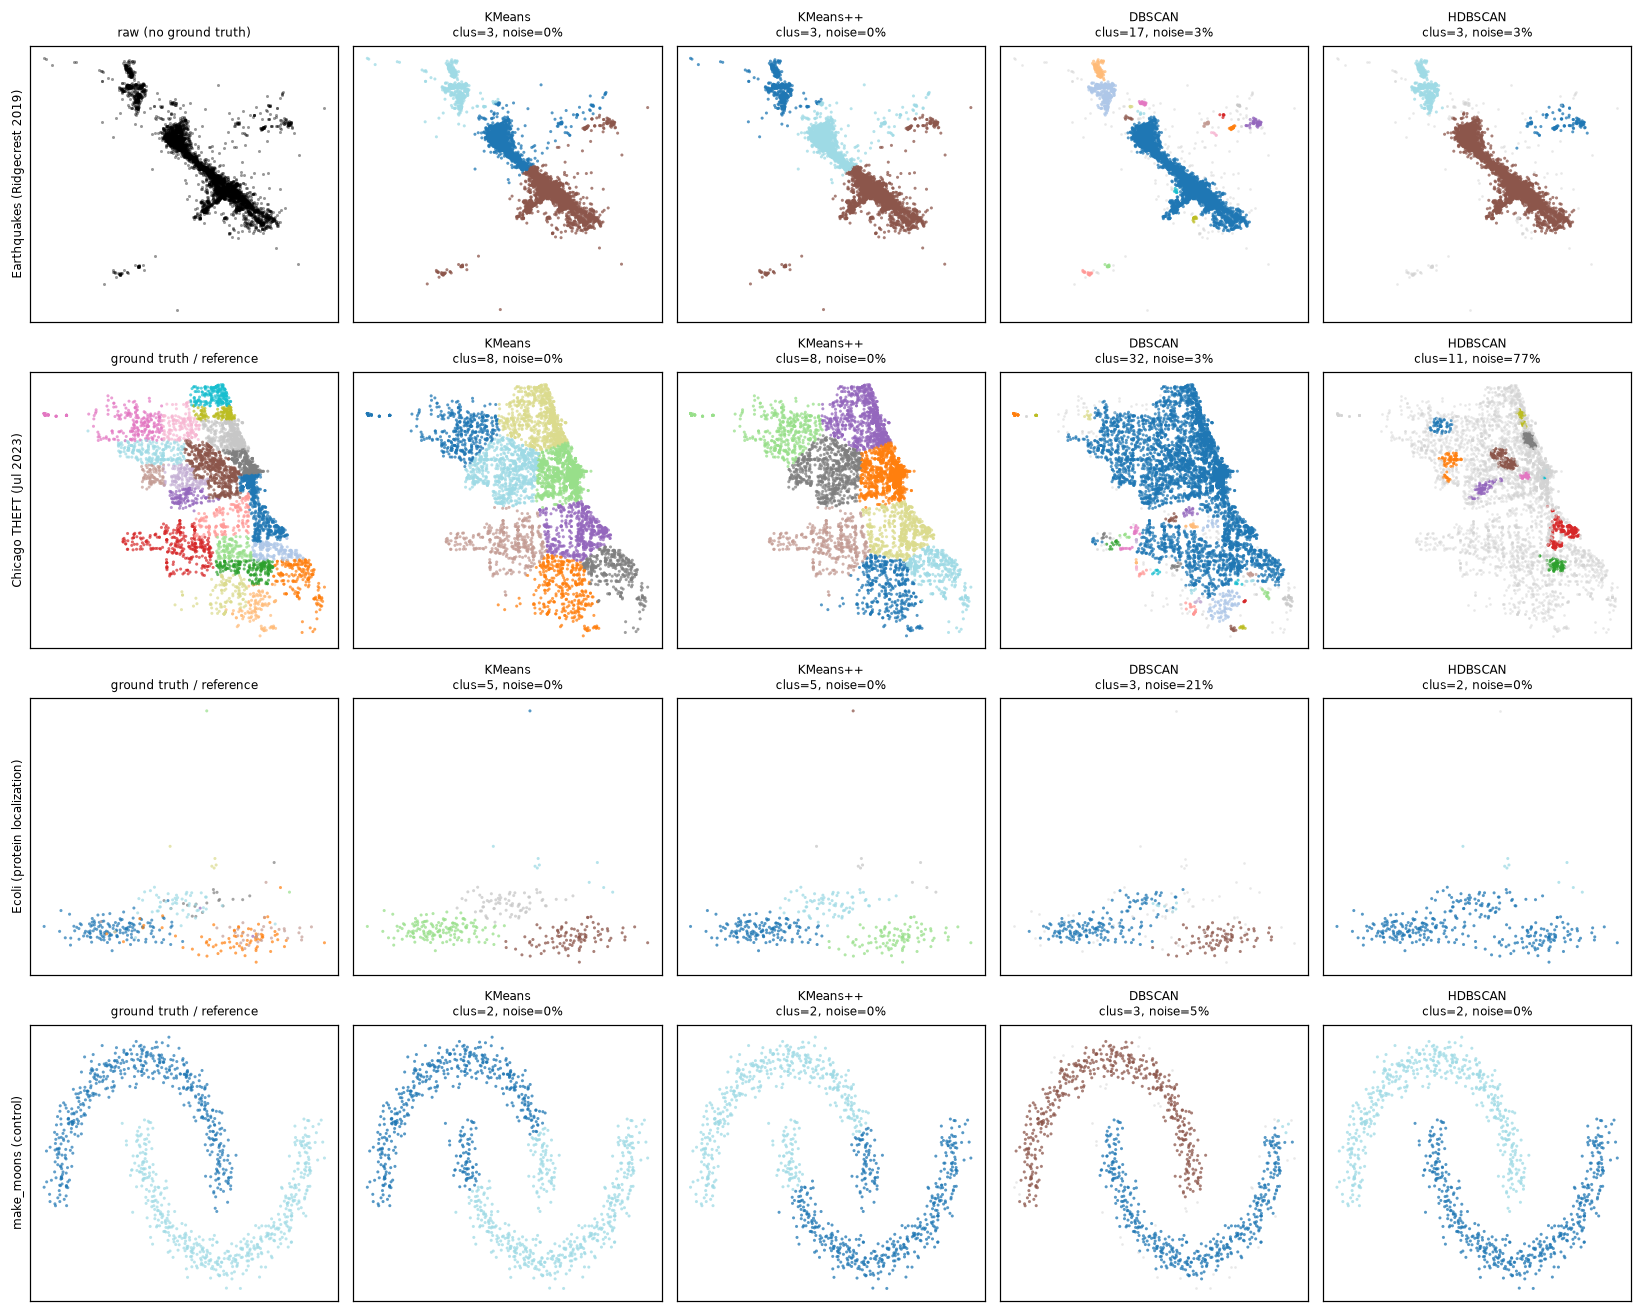

In [14]:
from sc4020.generate_figures import show_and_save_to
def plot_grid(
    dataset_names=("earthquakes", "chicago", "ecoli", "moons"),
    methods=("KMeans", "KMeans++", "DBSCAN", "HDBSCAN"),
):
    fig, axes = plt.subplots(
        len(dataset_names),
        len(methods) + 1,
        figsize=(3.0 * (len(methods) + 1), 3.0 * len(dataset_names)),
    )
    for i, dn in enumerate(dataset_names):
        p, y = PREP[dn], DATASETS[dn]["y"]
        Xp = p["X_plot"]
        xs, ys = (Xp[:, 1], Xp[:, 0]) if p["spatial"] else (Xp[:, 0], Xp[:, 1])
        ax = axes[i, 0]
        if y is not None:
            ax.scatter(xs, ys, c=y, s=4, cmap="tab20", alpha=0.7, linewidths=0)
            ax.set_title("ground truth / reference", fontsize=8)
        else:
            ax.scatter(xs, ys, c="k", s=4, alpha=0.4, linewidths=0)
            ax.set_title("raw (no ground truth)", fontsize=8)
        ax.set_ylabel(DATASETS[dn]["meta"]["name"], fontsize=8)
        for j, mn in enumerate(methods, start=1):
            lab = LABELS[(dn, mn)]
            ax = axes[i, j]
            noise = lab == -1
            ax.scatter(
                xs[~noise],
                ys[~noise],
                c=lab[~noise],
                s=4,
                cmap="tab20",
                alpha=0.75,
                linewidths=0,
            )
            if noise.any():
                ax.scatter(
                    xs[noise], ys[noise], c="lightgray", s=3, alpha=0.5, linewidths=0
                )
            r = main[(main.dataset == dn) & (main.method == mn)].iloc[0]
            ax.set_title(
                f"{mn}\nclus={r.n_clusters}, noise={r.noise_fraction:.0%}", fontsize=8
            )
    for ax in axes.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
    plt.tight_layout()
    show_and_save_to(plt.gcf(), FIG / "fig4_qualitative_grid.png")


plot_grid()

## 7. Ablation studies

Four ablations, each isolating one component.

### 7.1 Ablation A — distance metric (haversine vs Euclidean-on-degrees)

In [15]:
ab_metric = []
for name in ["earthquakes", "chicago"]:
    deg = DATASETS[name]["X"]
    rad = to_radians(deg)
    eps_r = EPS[name]
    eps_d = np.degrees(eps_r)  # naive equivalent in degrees
    for label, Xf, mtr, e in [
        ("haversine", rad, "haversine", eps_r),
        ("euclidean_deg", deg, "euclidean", eps_d),
    ]:
        r, _ = run(
            methods.dbscan(e, 5, metric=mtr),
            Xf,
            DATASETS[name]["y"],
            dataset=name,
            metric_used=label,
        )
        ab_metric.append(r)

ab_metric = pd.DataFrame(ab_metric)[
    ["dataset", "metric_used", "n_clusters", "noise_fraction", "silhouette", "ari"]
]
ab_metric.to_csv(OUT / "ablation_metric.csv", index=False)
ab_metric.round(4)

,dataset,metric_used,n_clusters,noise_fraction,silhouette,ari
0,earthquakes,haversine,17,0.0312,-0.3351,NaN
1,earthquakes,euclidean_deg,16,0.0394,-0.3275,NaN
2,chicago,haversine,32,0.0279,-0.2794,0.0131
3,chicago,euclidean_deg,48,0.0524,-0.3516,0.0550


### 7.2 Ablation B — feature scaling (Ecoli)

In [16]:
ab_scale = []
for label, Xf in [
    ("raw", DATASETS["ecoli"]["X"].astype(float)),
    ("standardized", standardize(DATASETS["ecoli"]["X"])),
]:
    k = BEST_K["ecoli"]
    kd = k_distance(Xf, 5)
    _, e = knee(kd)
    for mn, est in [
        ("KMeans++", methods.kmeans(k, n_init=10, random_state=RANDOM_STATE)),
        ("DBSCAN", methods.dbscan(e, 5)),
        ("HDBSCAN", methods.hdbscan(5)),
    ]:
        r, _ = run(est, Xf, DATASETS["ecoli"]["y"], scaling=label, method=mn)
        ab_scale.append(r)

ab_scale = pd.DataFrame(ab_scale)[
    ["scaling", "method", "n_clusters", "noise_fraction", "silhouette", "ari", "nmi"]
]
ab_scale.to_csv(OUT / "ablation_scaling.csv", index=False)
ab_scale.round(4)

,scaling,method,n_clusters,noise_fraction,silhouette,ari,nmi
0,raw,KMeans++,5,0.0000,0.3756,0.6945,0.6473
1,raw,DBSCAN,1,0.0744,NaN,0.0581,0.0991
2,raw,HDBSCAN,2,0.0060,0.3021,0.0382,0.1292
3,standardized,KMeans++,5,0.0000,0.4053,0.6971,0.6663
4,standardized,DBSCAN,1,0.0387,NaN,0.0403,0.1090
5,standardized,HDBSCAN,2,0.0030,0.5593,0.0381,0.1183


### 7.3 Ablation C — dimensionality (does DBSCAN degrade as dims grow?)

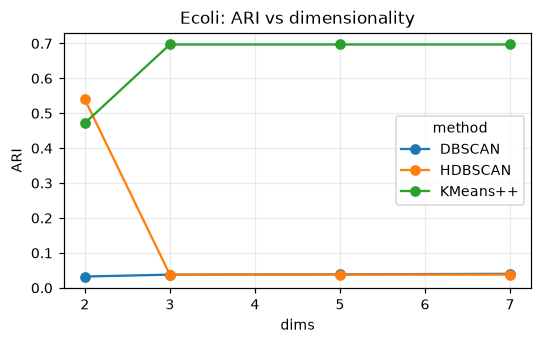

,dims,method,eps_knee,n_clusters,noise_fraction,silhouette,ari
0,2,KMeans++,0.5775,5,0.0000,0.4481,0.4719
1,2,DBSCAN,0.5775,1,0.0357,NaN,0.0325
2,2,HDBSCAN,0.5775,4,0.2143,0.4952,0.5398
3,3,KMeans++,0.7181,5,0.0000,0.5765,0.6971
4,3,DBSCAN,0.7181,1,0.0298,NaN,0.0380
5,3,HDBSCAN,0.7181,2,0.0030,0.5182,0.0381
6,5,KMeans++,1.6523,5,0.0000,0.4690,0.6971
7,5,DBSCAN,1.6523,2,0.0089,0.5867,0.0387
8,5,HDBSCAN,1.6523,2,0.0030,0.5873,0.0381
9,7,KMeans++,1.6088,5,0.0000,0.4053,0.6971


In [17]:
from sc4020.generate_figures import show_and_save_to
Xs_ec = standardize(DATASETS["ecoli"]["X"])
ab_dim = []
for d in [2, 3, 5, 7]:
    Xd = PCA(n_components=d, random_state=RANDOM_STATE).fit_transform(Xs_ec)
    kd = k_distance(Xd, 5)
    _, e = knee(kd)
    for mn, est in [
        (
            "KMeans++",
            methods.kmeans(BEST_K["ecoli"], n_init=10, random_state=RANDOM_STATE),
        ),
        ("DBSCAN", methods.dbscan(e, 5)),
        ("HDBSCAN", methods.hdbscan(5)),
    ]:
        r, _ = run(
            est, Xd, DATASETS["ecoli"]["y"], dims=d, method=mn, eps_knee=round(e, 4)
        )
        ab_dim.append(r)

ab_dim = pd.DataFrame(ab_dim)[
    ["dims", "method", "eps_knee", "n_clusters", "noise_fraction", "silhouette", "ari"]
]
ab_dim.to_csv(OUT / "ablation_dims.csv", index=False)

piv = ab_dim.pivot(index="dims", columns="method", values="ari")
piv.plot(marker="o", figsize=(5, 3.2))
plt.ylabel("ARI")
plt.title("Ecoli: ARI vs dimensionality")
plt.tight_layout()
show_and_save_to(plt.gcf(), FIG / "fig5_dimensionality.png")
ab_dim.round(4)

### 7.4 Ablation D — initialization: K-Means vs K-Means++ over 30 seeds

The honest expectation: K-Means++ mainly reduces *variance* and iteration count rather than improving the
best-case result. Report mean ± std — a single-seed number is the most common way these projects lose marks.

In [18]:
ab_init = []
for name in DATASETS:
    Xf, y, k = PREP[name]["X_fit"], DATASETS[name]["y"], BEST_K[name]
    for init in ["random", "k-means++"]:
        for seed in range(30):
            km = methods.kmeans(k, init=init, n_init=1, random_state=seed)
            lab = km.fit_predict(Xf)
            ab_init.append(
                dict(
                    dataset=name,
                    init=init,
                    seed=seed,
                    inertia=km.inertia_,
                    n_iter=km.n_iter_,
                    ari=(adjusted_rand_score(y, lab) if y is not None else np.nan),
                    silhouette=scores(Xf, lab)["silhouette"],
                )
            )

ab_init = pd.DataFrame(ab_init)
ab_init.to_csv(OUT / "ablation_init.csv", index=False)

init_summary = (
    ab_init.groupby(["dataset", "init"])
    .agg(
        inertia_mean=("inertia", "mean"),
        inertia_std=("inertia", "std"),
        iters_mean=("n_iter", "mean"),
        sil_mean=("silhouette", "mean"),
        sil_std=("silhouette", "std"),
        ari_mean=("ari", "mean"),
        ari_std=("ari", "std"),
    )
    .reset_index()
)
init_summary.to_csv(OUT / "ablation_init_summary.csv", index=False)
init_summary.round(4)

,dataset,init,inertia_mean,inertia_std,iters_mean,sil_mean,sil_std,ari_mean,ari_std
0,chicago,k-means++,0.0019,0.0000,14.9000,0.4119,0.0151,0.3764,0.0162
1,chicago,random,0.0019,0.0001,21.6333,0.4039,0.0161,0.3821,0.0177
2,earthquakes,k-means++,0.0190,0.0024,5.5667,0.5751,0.0659,NaN,NaN
3,earthquakes,random,0.0210,0.0030,7.6667,0.5197,0.0816,NaN,NaN
4,ecoli,k-means++,827.8839,110.2974,7.2333,0.3760,0.0507,0.6676,0.0670
5,ecoli,random,1033.9375,109.9834,15.1000,0.3030,0.0611,0.5879,0.1118
6,moons,k-means++,842.6221,0.0000,5.4000,0.4937,0.0000,0.4811,0.0000
7,moons,random,842.6221,0.0000,5.7000,0.4937,0.0000,0.4811,0.0000


### 7.5 DBSCAN parameter sensitivity heatmap — how narrow is the good region?

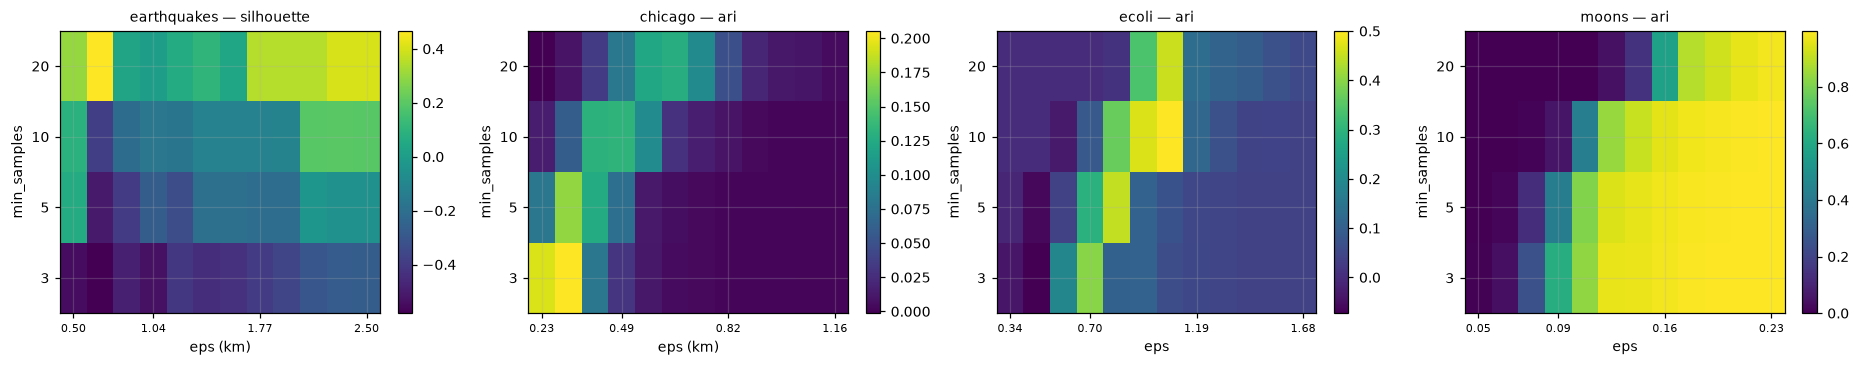

In [19]:
from sc4020.generate_figures import show_and_save_to
def eps_grid(name, n=12, lo=0.4, hi=2.0):
    base = EPS[name]
    return np.linspace(base * lo, base * hi, n)


MS_GRID = [3, 5, 10, 20]

sens_all = []
for name in DATASETS:
    p, y = PREP[name], DATASETS[name]["y"]
    for e in eps_grid(name):
        for ms in MS_GRID:
            lab = methods.dbscan(e, ms, metric=p["metric"]).fit_predict(p["X_fit"])
            r = scores(p["X_fit"], lab, y)
            sens_all.append(dict(dataset=name, eps=e, min_samples=ms, **r))

sens = pd.DataFrame(sens_all)
sens.to_csv(OUT / "dbscan_sensitivity.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, name in zip(axes, DATASETS):
    s = sens[sens.dataset == name]
    val = "ari" if s["ari"].notna().any() else "silhouette"
    grid = s.pivot(index="min_samples", columns="eps", values=val)
    im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="viridis")
    ax.set_yticks(range(len(grid.index)), grid.index)
    xt = np.linspace(0, len(grid.columns) - 1, 4).astype(int)
    scale = rad_to_km if PREP[name]["spatial"] else (lambda v: v)
    ax.set_xticks(xt, [f"{scale(grid.columns[i]):.2f}" for i in xt], fontsize=7)
    ax.set_xlabel("eps (km)" if PREP[name]["spatial"] else "eps")
    ax.set_ylabel("min_samples")
    ax.set_title(f"{name} — {val}", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
show_and_save_to(plt.gcf(), FIG / "fig6_dbscan_sensitivity.png")

## 8. Noise analysis — is DBSCAN's "noise" a bug or a feature?

The same mechanism, two domains, opposite verdicts:

* **Spatial (D1/D2):** isolated events genuinely are background. Labelling them noise is *correct* and is
  something K-Means cannot do at all — it forces every point into a hotspot.
* **Ecoli (D3):** the rare localization sites have 2–5 members. Labelling them noise *discards the signal a
  biologist most cares about* — rare classes are often the interesting ones.

In [20]:
noise_rows = []
for name in DATASETS:
    y = DATASETS[name]["y"]
    for mn in ["DBSCAN", "HDBSCAN"]:
        lab = LABELS[(name, mn)]
        noise = lab == -1
        row = dict(
            dataset=name,
            method=mn,
            noise_fraction=noise.mean(),
            n_noise=int(noise.sum()),
        )
        if y is not None and noise.any():
            # which true classes are disproportionately labelled noise?
            rate = pd.Series(y[noise]).value_counts() / pd.Series(y).value_counts()
            row["worst_class"] = int(rate.idxmax())
            row["worst_class_noise_rate"] = float(rate.max())
            sizes = pd.Series(y).value_counts()
            row["worst_class_size"] = int(sizes[rate.idxmax()])
        noise_rows.append(row)

noise_df = pd.DataFrame(noise_rows)
noise_df.to_csv(OUT / "noise_analysis.csv", index=False)
noise_df.round(4)

,dataset,method,noise_fraction,n_noise,worst_class,worst_class_noise_rate,worst_class_size
0,earthquakes,DBSCAN,0.0312,176,NaN,NaN,NaN
1,earthquakes,HDBSCAN,0.0293,165,NaN,NaN,NaN
2,chicago,DBSCAN,0.0279,145,22.0,1.000,1.0
3,chicago,HDBSCAN,0.7670,3979,3.0,1.000,219.0
4,ecoli,DBSCAN,0.2083,70,2.0,1.000,2.0
5,ecoli,HDBSCAN,0.0030,1,2.0,0.500,2.0
6,moons,DBSCAN,0.0480,48,1.0,0.056,500.0
7,moons,HDBSCAN,0.0000,0,NaN,NaN,NaN


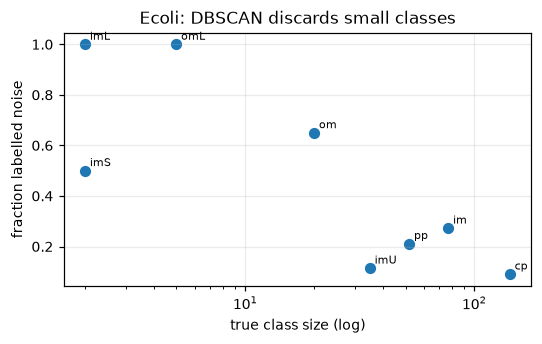

,true,size,noise_rate,site
0,0,143,0.091,cp
1,1,77,0.273,im
2,2,2,1.000,imL
3,3,2,0.500,imS
4,4,35,0.114,imU
5,5,20,0.650,om
6,6,5,1.000,omL
7,7,52,0.212,pp


In [21]:
from sc4020.generate_figures import show_and_save_to
# Ecoli: noise rate as a function of true class size — the rare-class question, quantified
y = DATASETS["ecoli"]["y"]
lab = LABELS[("ecoli", "DBSCAN")]
tab = (
    pd.DataFrame({"true": y, "noise": lab == -1})
    .groupby("true")
    .agg(size=("noise", "size"), noise_rate=("noise", "mean"))
    .reset_index()
)
tab["site"] = pd.Categorical(ec_df["site"]).categories[tab["true"]]

plt.figure(figsize=(5, 3.2))
plt.scatter(tab["size"], tab["noise_rate"], s=40)
for _, r in tab.iterrows():
    plt.annotate(
        r["site"],
        (r["size"], r["noise_rate"]),
        fontsize=7,
        xytext=(3, 3),
        textcoords="offset points",
    )
plt.xscale("log")
plt.xlabel("true class size (log)")
plt.ylabel("fraction labelled noise")
plt.title("Ecoli: DBSCAN discards small classes")
plt.tight_layout()
show_and_save_to(plt.gcf(), FIG / "fig7_noise_vs_classsize.png")
tab.round(3)

## 9. Core analysis — do internal metrics pick the right method?

This is the section that justifies including a labelled dataset in a spatial-application paper.

Procedure: on the datasets with labels, rank the methods by each **internal** metric, then by **ARI**.
If the rankings disagree, then the internal metrics we are forced to rely on for D1/D2 are unreliable
guides — and every conclusion drawn from them needs a caveat.

In [22]:
labelled = [n for n in DATASETS if DATASETS[n]["y"] is not None]


def ranking(df, col, higher_is_better=True):
    s = df.set_index("method")[col]
    return s.sort_values(ascending=not higher_is_better).index.tolist()


cmp_rows = []
for name in labelled:
    sub = main[main.dataset == name]
    cmp_rows.append(
        dict(
            dataset=name,
            by_silhouette=" > ".join(ranking(sub, "silhouette")),
            by_davies_bouldin=" > ".join(ranking(sub, "davies_bouldin", False)),
            by_calinski=" > ".join(ranking(sub, "calinski_harabasz")),
            by_ari=" > ".join(ranking(sub, "ari")),
            agrees=ranking(sub, "silhouette")[0] == ranking(sub, "ari")[0],
        )
    )

agreement = pd.DataFrame(cmp_rows)
agreement.to_csv(OUT / "metric_agreement.csv", index=False)
for _, r in agreement.iterrows():
    print(f"\n[{r.dataset}]")
    print("  silhouette says:", r.by_silhouette)
    print("  ARI        says:", r.by_ari)
    print("  top-1 agree:", r.agrees)


[chicago]
  silhouette says: HDBSCAN > KMeans > KMeans++ > DBSCAN
  ARI        says: KMeans > KMeans++ > DBSCAN > HDBSCAN
  top-1 agree: False

[ecoli]
  silhouette says: HDBSCAN > KMeans > KMeans++ > DBSCAN
  ARI        says: KMeans++ > KMeans > DBSCAN > HDBSCAN
  top-1 agree: False

[moons]
  silhouette says: KMeans > KMeans++ > HDBSCAN > DBSCAN
  ARI        says: HDBSCAN > DBSCAN > KMeans++ > KMeans
  top-1 agree: False


In [23]:
# Quantify the bias: correlation between each internal metric and ARI across ALL runs we have
pool = pd.concat(
    [
        main[main.dataset.isin(labelled)][
            ["silhouette", "davies_bouldin", "calinski_harabasz", "ari"]
        ],
        sens[sens.dataset.isin(labelled)][
            ["silhouette", "davies_bouldin", "calinski_harabasz", "ari"]
        ],
    ]
).dropna()

corr = pool.corr(method="spearman")["ari"].drop("ari")
print("Spearman correlation with ARI (n=%d runs):" % len(pool))
print(corr.round(3))
print(
    "\nDavies-Bouldin is lower-is-better, so a NEGATIVE correlation here is the 'good' direction."
)

Spearman correlation with ARI (n=124 runs):
silhouette           0.181
davies_bouldin       0.791
calinski_harabasz    0.417
Name: ari, dtype: float64

Davies-Bouldin is lower-is-better, so a NEGATIVE correlation here is the 'good' direction.


## 10. Export tables for the report

Produces LaTeX-ready tables in `results/`. Paste with `\input{}` rather than retyping numbers —
retyping is how the paper ends up disagreeing with the code.

In [24]:
from sc4020.generate_figures import to_latex_table
for df, name, caption, label in [
    (summary, "tab1_datasets.tex", "Datasets used in this study.", "tab:datasets"),
    (
        main.round(3),
        "tab2_main.tex",
        "Main comparison across all datasets and methods.",
        "tab:main",
    ),
    (
        init_summary.round(3),
        "tab3_init.tex",
        "Initialization ablation over 30 seeds (mean and standard deviation).",
        "tab:init",
    ),
    (
        ab_scale.round(3),
        "tab4_scaling.tex",
        "Feature-scaling ablation on Ecoli.",
        "tab:scaling",
    ),
    (ab_dim.round(3), "tab5_dims.tex", "Dimensionality ablation on Ecoli.", "tab:dims"),
]:
    print("wrote", to_latex_table(df, OUT / name, caption, label))

print("\nAll artefacts:")
for p in sorted(list(OUT.glob("*")) + list(FIG.glob("*"))):
    print(" ", p)

wrote /home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/hotspot/notebook/tab1_datasets.tex
wrote /home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/hotspot/notebook/tab2_main.tex
wrote /home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/hotspot/notebook/tab3_init.tex
wrote /home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/hotspot/notebook/tab4_scaling.tex
wrote /home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/hotspot/notebook/tab5_dims.tex

All artefacts:
  /home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/hotspot/notebook/ablation_dims.csv
  /home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/hotspot/notebook/ablation_init.csv
  /home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/hotspot/notebook/ablation_init_summary.csv
  /home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine

## 11. Reproducibility record

Paste this into the paper's reproducibility paragraph.

In [25]:
import sys, sklearn

record = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "random_state": RANDOM_STATE,
    "n_seeds_init_ablation": 30,
    "datasets": {
        k: dict(n=int(len(v["X"])), dims=int(v["X"].shape[1]))
        for k, v in DATASETS.items()
    },
    "chosen_k": BEST_K,
    "chosen_eps": {
        k: (round(rad_to_km(v), 4) if PREP[k]["spatial"] else round(v, 5))
        for k, v in EPS.items()
    },
}
Path(OUT / "repro.json").write_text(json.dumps(record, indent=2))
print(json.dumps(record, indent=2))

{
  "python": "3.13.15",
  "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.43",
  "numpy": "2.5.3",
  "pandas": "3.0.5",
  "sklearn": "1.9.1",
  "random_state": 42,
  "n_seeds_init_ablation": 30,
  "datasets": {
    "earthquakes": {
      "n": 5635,
      "dims": 2
    },
    "chicago": {
      "n": 5188,
      "dims": 2
    },
    "ecoli": {
      "n": 336,
      "dims": 7
    },
    "moons": {
      "n": 1000,
      "dims": 2
    }
  },
  "chosen_k": {
    "earthquakes": 3,
    "chicago": 8,
    "ecoli": 5,
    "moons": 2
  },
  "chosen_eps": {
    "earthquakes": 1.2487,
    "chicago": 0.5801,
    "ecoli": 0.83954,
    "moons": 0.11323
  }
}


---
## What to do next

**Division of work across four people** — each owns a section end-to-end:

| Person | Sections | Deliverable |
|---|---|---|
| P1 Data | 1–2 | all three datasets cached, metric choice justified |
| P2 Centroid | 4.1, 7.4 | k selection + init ablation with mean±std |
| P3 Density | 4.2, 7.5, 8 | eps heuristic, sensitivity heatmap, noise analysis |
| P4 Eval/Report | 3, 5–6, 9–10 | harness, figures, LaTeX tables, integration |

**Before you write a word of the paper**, run everything once and look at `results/metric_agreement.csv`.
If silhouette and ARI disagree on which method wins, that disagreement is your paper's main finding, and
Section 9 becomes the centrepiece rather than an appendix.

**Known extension points** if you want more depth:
- Add OPTICS as a fifth method (`sklearn.cluster.OPTICS`) — the missing link between DBSCAN and HDBSCAN
- Cluster earthquakes on (lat, lon, depth) instead of (lat, lon) and see whether 3-D structure changes fault segmentation
- Add a temporal dimension to the crime data — hotspots move, and single-snapshot clustering hides that